# Sprint 12: Detection Training Validation Demonstration

This notebook demonstrates the complete cell detection learning and verification pipeline, verifying that our baseline detection model can train and learn from Gaussian target heatmaps.

## What is demonstrated:
1. **Model & Data Setup**: Instantiating the baseline detector and a custom dummy dataset.
2. **Evaluator & Trainer Setup**: Setting up the evaluator and trainer with best checkpoint saving.
3. **Training & Validation**: Running a complete training and validation experiment.
4. **Evaluation**: Compiling precision, recall, and F1 scores.
5. **Visualization**: Plotting loss curves and metric improvements over epochs.
6. **Inference & Peak Detection**: Executing `predict()` to obtain predicted heatmaps and coordinates.
7. **Prediction vs Target & 3D Plots**: Visualizing the output heatmaps, peak coordinates, and comparisons.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
import tempfile

# Imports from codebase
from src.models.detection.baseline_detector import BaselineDetector
from src.losses.detection_loss import DetectionLoss
from src.postprocessing.peak_detector import PeakDetector
from src.metrics.detection_metrics import DetectionMetrics
from src.evaluation.evaluator import DetectionEvaluator
from src.trainer.trainer import Trainer
from src.inference.predict import predict
from src.visualization.training_visualizer import (
    plot_loss_curves,
    visualize_prediction_heatmap,
    visualize_target_heatmap,
    visualize_peak_detection,
    compare_prediction_vs_target,
    visualize_detected_coordinates_3d
)

# Set random seed for reproducibility
torch.manual_seed(42)

## 1. Create Dummy Dataset and DataLoaders

In [2]:
class DemoDataset(Dataset):
    def __init__(self, size=4):
        self.size = size
        
    def __len__(self):
        return self.size
        
    def __getitem__(self, idx):
        # We simulate a 3D volume of shape (1, 8, 32, 32) with a channel dimension
        # to comply with the DetectionEvaluator channel consistency requirements.
        image = torch.zeros((1, 8, 32, 32), dtype=torch.float32)
        image[0, 3:6, 14:18, 14:18] = 1.0 # mock cell
        
        target = torch.zeros((1, 8, 32, 32), dtype=torch.float32)
        target[0, 4, 16, 16] = 1.0 # Gaussian peak target at (4.0, 16.0, 16.0)
        
        # Ground truth coordinates
        positions = torch.tensor([[4.0, 16.0, 16.0]], dtype=torch.float32)
        
        return {
            "image": image,
            "target": target,
            "positions": positions
        }

train_ds = DemoDataset(size=8)
val_ds = DemoDataset(size=4)

train_loader = DataLoader(train_ds, batch_size=2, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=2, shuffle=False)

print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}")

Train batches: 4, Val batches: 2


## 2. Initialize Model, Loss, Metrics, Peak Detector, and Evaluator

In [3]:
# Instantiate model, loss, peak detector, metrics, evaluator
model = BaselineDetector(in_channels=1, hidden_channels=8, out_channels=1)
loss_fn = DetectionLoss()
peak_detector = PeakDetector(threshold=0.5)
metrics = DetectionMetrics(distance_threshold=10.0)

evaluator = DetectionEvaluator(
    model=model,
    val_loader=val_loader,
    peak_detector=peak_detector,
    metrics=metrics,
    loss_fn=loss_fn
)

## 3. Initialize Trainer and Run Training Experiment

We train the model for 5 epochs, enabling automatic evaluation after every epoch, and saving the best checkpoint to a temporary file.

In [4]:
temp_dir = tempfile.TemporaryDirectory()
checkpoint_path = Path(temp_dir.name) / "best_model.pt"

trainer = Trainer(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    loss_fn=loss_fn,
    lr=1e-3,
    step_size=3,
    gamma=0.5
)

# Run fit
history = trainer.fit(
    num_epochs=5,
    evaluator=evaluator,
    best_checkpoint_path=checkpoint_path
)

print("\nTraining complete! History keys:", list(history.keys()))
for key, values in history.items():
    print(f"{key}: {[f'{v:.4f}' if isinstance(v, float) else v for v in values]}")


Training complete! History keys: ['train_loss', 'val_loss', 'validation_loss', 'precision', 'recall', 'f1_score', 'learning_rate']
train_loss: ['0.2595', '0.2546', '0.2452', '0.2313', '0.2190']
val_loss: ['0.2568', '0.2500', '0.2353', '0.2241', '0.2099']
validation_loss: ['0.2568', '0.2500', '0.2353', '0.2241', '0.2099']
precision: ['0.0000', '0.0000', '0.0000', '0.0000', '0.0000']
recall: ['0.0000', '0.0000', '0.0000', '0.0000', '0.0000']
f1_score: ['0.0000', '0.0000', '0.0000', '0.0000', '0.0000']
learning_rate: ['0.0010', '0.0010', '0.0010', '0.0005', '0.0005']


## 4. Plot Loss and Metrics Curves

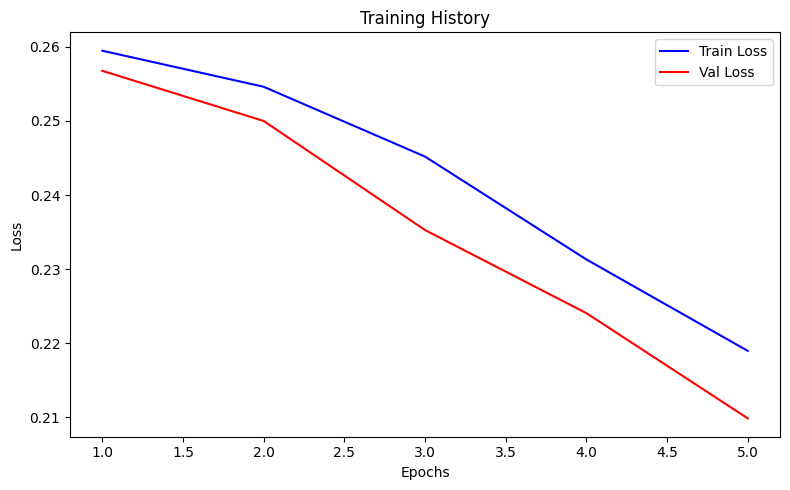

In [5]:
plot_loss_curves(history)

## 5. Perform Inference and Peak Detection

We use the saved best checkpoint to run inference on a sample volume and extract predicted coordinates.

In [6]:
if checkpoint_path.exists():
    trainer.load_checkpoint(checkpoint_path)
else:
    print("No best checkpoint was saved, using current model state.")

# Get one validation sample volume
sample = val_ds[0]
volume = sample["image"]
target_heatmap = sample["target"]
gt_coords = sample["positions"]

# Run inference
pred_heatmap, pred_coords = predict(trainer.model, volume, peak_detector=peak_detector)

print(f"Prediction heatmap shape: {pred_heatmap.shape}")
print(f"Predicted coordinates (M, 3):\n{pred_coords}")
print(f"Ground Truth coordinates (N, 3):\n{gt_coords}")

Prediction heatmap shape: torch.Size([1, 8, 32, 32])
Predicted coordinates (M, 3):
tensor([], size=(0, 3))
Ground Truth coordinates (N, 3):
tensor([[ 4., 16., 16.]])


## 6. Visualize Prediction and Target Slices

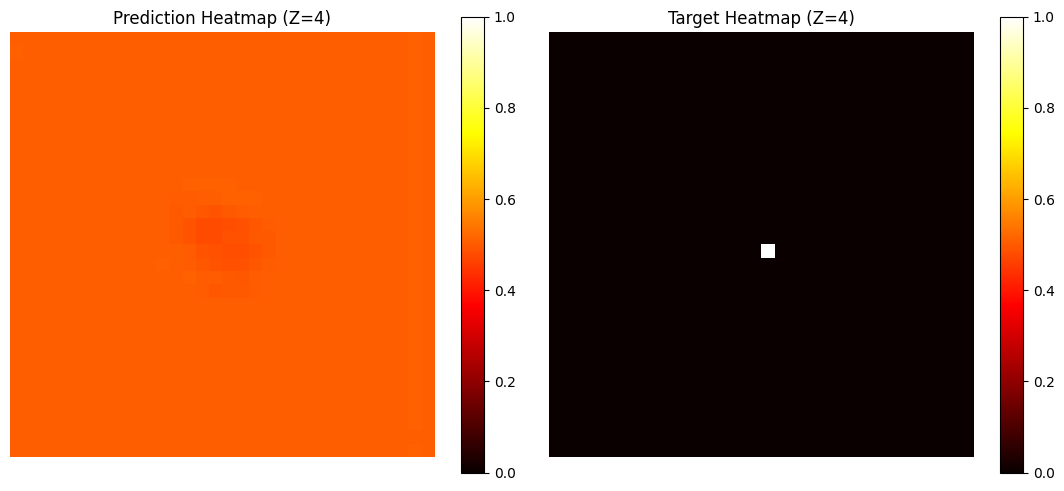

In [7]:
# Compare side-by-side on slice Z=4
compare_prediction_vs_target(pred_heatmap, target_heatmap, z_slice=4)

## 7. Visualize Peak Detection Overlay and 3D Coordinates

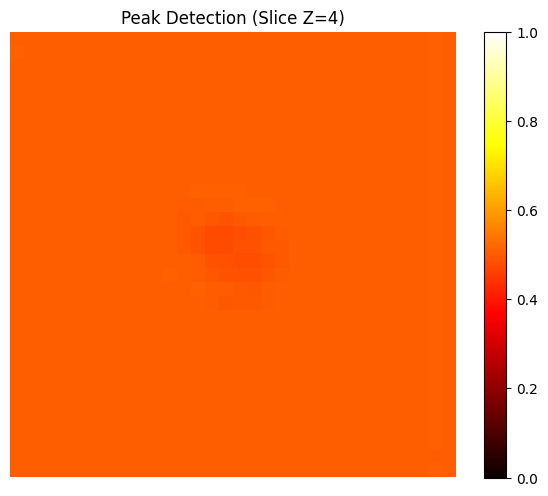

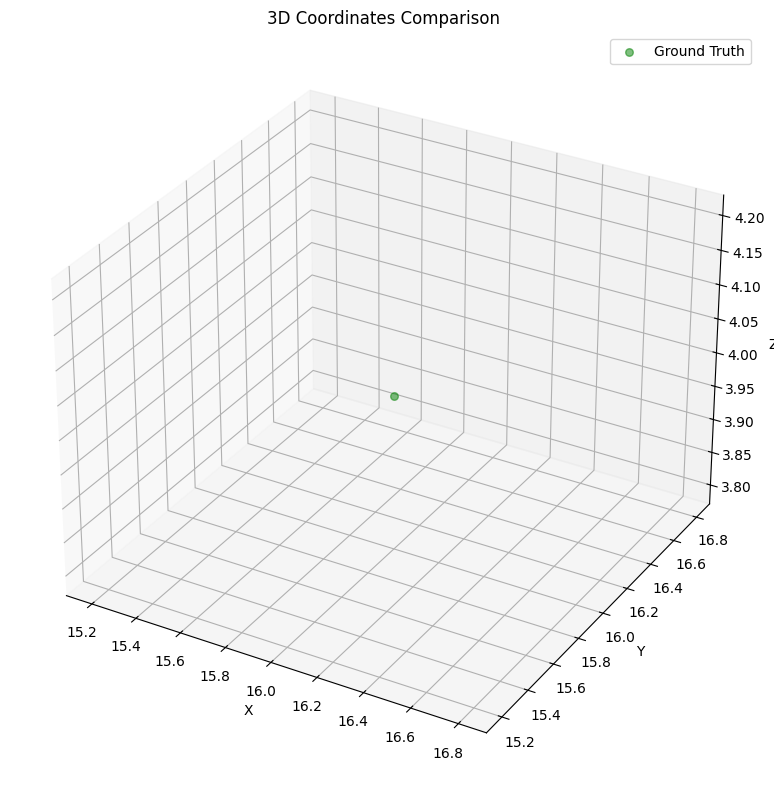

In [8]:
# Visualize peak detection on Z=4 slice
visualize_peak_detection(pred_heatmap, pred_coords, z_slice=4)

# Visualize 3D coordinates comparison
visualize_detected_coordinates_3d(pred_coords, gt_coords)

# Clean up temp dir
temp_dir.cleanup()